강의 출처 : 권철민, 딥러닝 CNN 완벽 가이드(tf.keras version)

In [ ]:
# !pip install tensorflow

In [1]:
from tensorflow.keras.datasets import fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

print("train dataset shape:", train_images.shape, train_labels.shape)
print("test dataset shape:", test_images.shape, test_labels.shape)


train dataset shape: (60000, 28, 28) (60000,)
test dataset shape: (10000, 28, 28) (10000,)


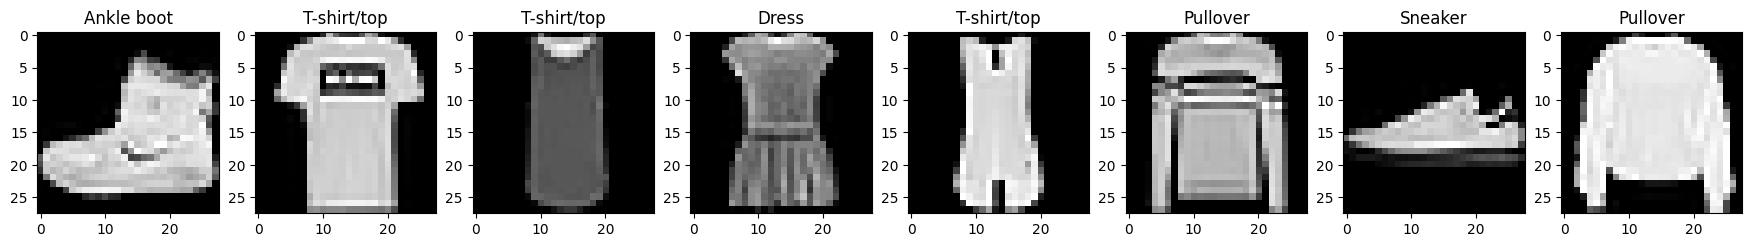

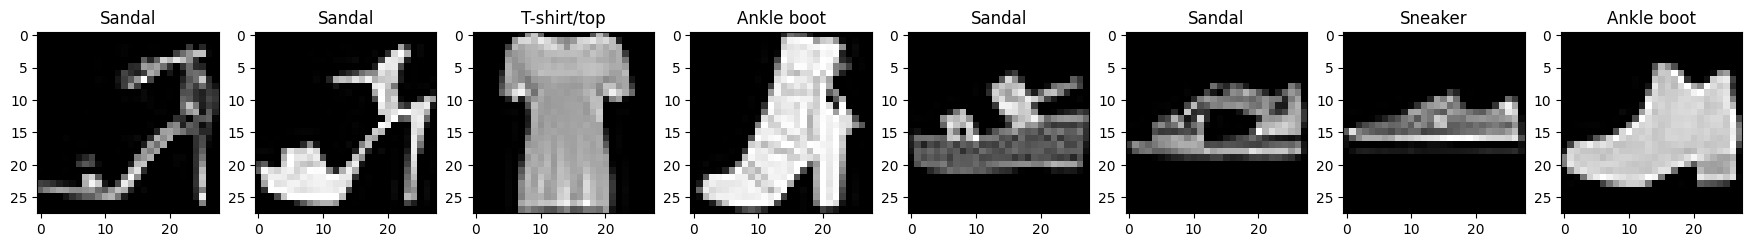

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
def show_images(images, labels, ncols=8):
    figure, axs = plt.subplots(figsize=(22,6), nrows=1, ncols=ncols)
    for i in range(ncols):
        axs[i].imshow(images[i], cmap='gray')
        axs[i].set_title(class_names[labels[i]])

show_images(train_images[:8], train_labels[:8], ncols=8)
show_images(train_images[8:16], train_labels[8:16], ncols=8)

In [3]:
import numpy as np

In [4]:
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

def get_preprocessed_data(images, labels):
    images = np.array(images/255.0, dtype=np.float32)
    labels = np.array(labels, dtype=np.float32)
    return images, labels

train_images, train_labels = get_preprocessed_data(train_images, train_labels)
test_images, test_labels = get_preprocessed_data(test_images, test_labels)

print("train dataset shape:", train_images.shape, train_labels.shape)
print("test dataset shape:", test_images.shape, test_labels.shape)

train dataset shape: (60000, 28, 28) (60000,)
test dataset shape: (10000, 28, 28) (10000,)


In [5]:
train_images[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [6]:
INPUT_SIZE = 28

In [7]:
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Sequential

model = Sequential([
    Flatten(input_shape=(INPUT_SIZE, INPUT_SIZE)),
    Dense(100, activation='relu'),
    Dense(30, activation='relu'),
    Dense(10, activation='softmax')]
)
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
I0000 00:00:1792585311.234277    1743 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792585311.236525    1743 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         3,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,840 (319.69 KB)

 Trainable params: 81,840 (319.69 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.metrics import Accuracy

model.compile(optimizer=Adam(0.001), 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

In [9]:
from tensorflow.keras.utils import to_categorical

train_oh_labels = to_categorical(train_labels)
test_oh_labels = to_categorical(test_labels)

print(train_oh_labels.shape, test_oh_labels.shape)

(60000, 10) (10000, 10)


In [10]:
history = model.fit(x=train_images, 
                    y=train_oh_labels, 
                    batch_size=32, 
                    epochs=20, 
                    verbose=1)

Epoch 1/20
  74/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4460 - loss: 1.6248  

I0000 00:00:1792585323.002249    1786 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8185 - loss: 0.5189
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8629 - loss: 0.3826
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8747 - loss: 0.3432
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8828 - loss: 0.3218
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8891 - loss: 0.3029
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8920 - loss: 0.2904
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8972 - loss: 0.2764
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9020 - loss: 0.2662
Epoch 9/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9047 - loss: 0.2556
Epoch 10/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9082 - loss: 0.2476
Epoch 11/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9085 - loss: 0.2416
Epoch 12/20
1875/1875 ━━━━━━━━━━━━━━━━━━━

In [11]:
print(history.history['loss'])
print(history.history['accuracy'])

[0.5188609957695007, 0.3826199471950531, 0.34320271015167236, 0.32180315256118774, 0.3028711676597595, 0.290353387594223, 0.2763804495334625, 0.2662368714809418, 0.25561201572418213, 0.2476276010274887, 0.2416440099477768, 0.23421159386634827, 0.2268097847700119, 0.22060361504554749, 0.21425490081310272, 0.2088240683078766, 0.2053796947002411, 0.2008974254131317, 0.19510912895202637, 0.19054721295833588]
[0.8184999823570251, 0.86285001039505, 0.8747333288192749, 0.8827999830245972, 0.8890500068664551, 0.8919666409492493, 0.8972333073616028, 0.9020166397094727, 0.904699981212616, 0.9081666469573975, 0.908466637134552, 0.9119499921798706, 0.9140666723251343, 0.916700005531311, 0.9192000031471252, 0.9214833378791809, 0.921833336353302, 0.9240000247955322, 0.925849974155426, 0.9276000261306763]


In [12]:
test_images.shape

(10000, 28, 28)

In [13]:
pred_proba = model.predict(test_images)
print(pred_proba.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
(10000, 10)


In [14]:
pred_proba = model.predict(np.expand_dims(test_images[0], axis=0))
print('softmax output:', pred_proba)
pred = np.argmax(np.squeeze(pred_proba))
print('predicted class value:', pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step
softmax output: [[4.3837964e-09 2.7072280e-11 1.1539158e-07 5.1084254e-07 3.9602227e-07
  8.4649277e-05 1.2484614e-07 5.7001957e-03 1.4314280e-07 9.9421388e-01]]
predicted class value: 9


In [15]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print('target class value:', test_labels[0], 'predicted class valud:', pred)

target class value: 9.0 predicted class valud: 9


In [16]:
model.evaluate(test_images, test_oh_labels, batch_size=64)

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8862 - loss: 0.3607


[0.3607441484928131, 0.8862000107765198]

In [ ]:
# validation dataset을 이용하여 학습 수행

# 일반적으로 fit() 수행시 검증 데이터 셋을 이용하여 과적합이 발생하는지 모니터링 한다.
# fit()을 수행시 iteration을 반복하기 때문에 hyper parameter(learning rate) 변경 등의 작업이 어려움.
# fit() iteration시 여러 작업을 하기위해 callback 객체를 가짐

# 검증 데이터 셋을 fit()에 적용하여,
# 과적합이나 성능이 좋아지지않을때 callback 기능을 사용하여 learning rate 보정작업을 수행가능하다.

In [17]:
import numpy as np
import pandas as pd


In [19]:
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

def get_preprocessed_data(images, labels):
    images = np.array(images/255.0, dtype=np.float32)
    labels = np.array(labels, dtype=np.float32)
    return images, labels

train_images, train_labels = get_preprocessed_data(train_images, train_labels)
test_images, test_labels = get_preprocessed_data(test_images, test_labels)

print("train dataset shape:", train_images.shape, train_labels.shape)
print("test dataset shape:", test_images.shape, test_labels.shape)

train dataset shape: (60000, 28, 28) (60000,)
test dataset shape: (10000, 28, 28) (10000,)


In [20]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

tr_images, val_images, tr_labels, val_labels = train_test_split(train_images, train_labels,
                                                                test_size=0.15,
                                                                random_state=2021)
print('train과 validation shape:', tr_images.shape, tr_labels.shape,
                                 val_images.shape, val_labels.shape)

tr_oh_labels = to_categorical(tr_labels)
val_oh_labels = to_categorical(val_labels)

print('after OHE:', train_oh_labels.shape, val_oh_labels.shape)

train과 validation shape: (51000, 28, 28) (51000,) (9000, 28, 28) (9000,)
after OHE: (60000, 10) (9000, 10)


In [21]:
INPUT_SIZE = 28

In [22]:
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

model = Sequential([
    Flatten(input_shape=(INPUT_SIZE, INPUT_SIZE)),
    Dense(100, activation='relu'),
    Dense(30, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer=Adam(0.001),
                loss='CategoricalCrossentropy',
                metrics=['accuracy'])

history = model.fit(x=tr_images, y=tr_oh_labels, batch_size=32,
                    validation_data=(val_images, val_oh_labels),
                    epochs=20, verbose=1)

Epoch 1/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8142 - loss: 0.5283 - val_accuracy: 0.8406 - val_loss: 0.4389
Epoch 2/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8618 - loss: 0.3833 - val_accuracy: 0.8593 - val_loss: 0.3915
Epoch 3/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8732 - loss: 0.3472 - val_accuracy: 0.8643 - val_loss: 0.3628
Epoch 4/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8827 - loss: 0.3207 - val_accuracy: 0.8748 - val_loss: 0.3360
Epoch 5/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8887 - loss: 0.3059 - val_accuracy: 0.8749 - val_loss: 0.3374
Epoch 6/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8906 - loss: 0.2913 - val_accuracy: 0.8700 - val_loss: 0.3624
Epoch 7/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8955 - loss: 0.2785 - val_accuracy: 0.8796 - val_loss: 0.3258
Epoch 8/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8982 - loss: 0.2693 - 

In [23]:
print(history.history['loss'])
print(history.history['accuracy'])
print(history.history['val_loss'])
print(history.history['val_accuracy'])

[0.5283176898956299, 0.3832993507385254, 0.3471754789352417, 0.3207378685474396, 0.30592983961105347, 0.29128172993659973, 0.2785392701625824, 0.2693064212799072, 0.25847193598747253, 0.25185665488243103, 0.24281592667102814, 0.2358323335647583, 0.22909942269325256, 0.2203700840473175, 0.2162846177816391, 0.20869064331054688, 0.20502138137817383, 0.1989412009716034, 0.1937674582004547, 0.192461296916008]
[0.8141568899154663, 0.8617647290229797, 0.8731960654258728, 0.8826862573623657, 0.8886666893959045, 0.8906078338623047, 0.8954705595970154, 0.8981764912605286, 0.9037451148033142, 0.9046078324317932, 0.9084901809692383, 0.9101372361183167, 0.914588212966919, 0.9153921604156494, 0.9177451133728027, 0.9211961030960083, 0.9221176505088806, 0.9238823652267456, 0.927117645740509, 0.9270195960998535]
[0.4388800263404846, 0.3914739191532135, 0.3627779185771942, 0.33602815866470337, 0.33735716342926025, 0.3624040484428406, 0.3257598876953125, 0.3243201673030853, 0.31463393568992615, 0.3068839

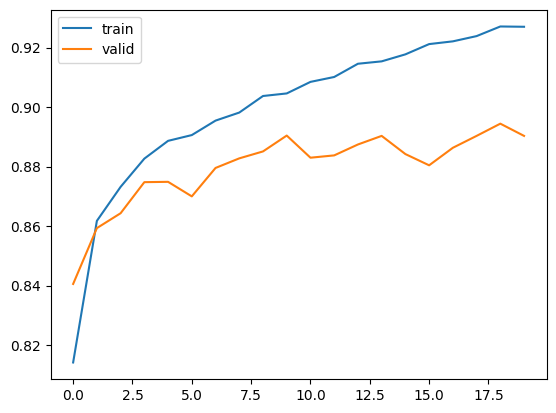

In [24]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='valid')
plt.legend()

In [ ]:
# Sequential Model을 이용하여 keras 모델 생성
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Sequential

INPUT_SIZE = 28

model = Sequential([
    Flatten(input_shape=(INPUT_SIZE, INPUT_SIZE)),
    Dense(100, activation='relu', name='Dense1'),
    Dense(30, activation='relu', name='Dense'),
    Dense(10, activation='softmax')
])

model.summary()

model1 = Sequential()
model1.add(Flatten(input_shape=(INPUT_SIZE, INPUT_SIZE)))
model1.add(Dense(100, activation='relu'))
model1.add(Dense(30, activation='relu'))
model1.add(Dense(10, activation='softmax'))

model1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 30)             │         3,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,840 (319.69 KB)

 Trainable params: 81,840 (319.69 KB)

...

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 30)             │         3,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,840 (319.69 KB)

 Trainable params: 81,840 (319.69 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
from tensorflow.keras.layers import Input, Flatten, Dense
from tensorflow.keras.models import Model

input_tensor = Input(shape=(INPUT_SIZE, INPUT_SIZE))
x = Flatten()(input_tensor)
x = Dense(100, activation='relu')(x)
x = Dense(30, activation='relu')(x)
output = Dense(10, activation='softmax')(x)

model = Model(inputs=input_tensor, outputs=output)

model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 30)             │         3,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,840 (319.69 KB)

 Trainable params: 81,840 (319.69 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# Custom 한 Dense Layer 생성하기 
from tensorflow.keras.layers import Layer, Input
from tensorflow.keras.models import Model
import tensorflow as tf

class CustomDense(tf.keras.layers.Layer):
    def __init__(self, units=32):
        super(CustomDense, self).__init__()
        self.units = units

    def build(self, input_shape):
        self.w = self.add_weight(
            shape=(input_shape[-1], self.units),
            initializer="random_normal",
            trainable=True
        )
        self.b = self.add_weight(
             shape=(self.units,), initializer="random_normal", trainable=True
        )

    def call(self, inputs):
        return tf.matmul(inputs, self.w) + self.b

inputs = Input((4,))
outputs = CustomDense(10,)(inputs)
model = Model(inputs, outputs)
model.summary()



Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_dense_2 (CustomDense)    │ (None, 10)             │            50 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50 (200.00 B)

 Trainable params: 50 (200.00 B)

 Non-trainable params: 0 (0.00 B)

In [31]:
# Functional API는 객체 생성 부분과 Callable 인자 입력 부분을 별도로 수행해도 무방
inputs = Input((4,))

my_layer = CustomDense(10)
outputs = my_layer(inputs)
 
model = Model(inputs, outputs)
model.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_dense_3 (CustomDense)    │ (None, 10)             │            50 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50 (200.00 B)

 Trainable params: 50 (200.00 B)

 Non-trainable params: 0 (0.00 B)

In [32]:
layers_list = [Input((4,)), CustomDense(10), CustomDense(10), tf.keras.layers.ReLU()]

inputs = None  # 모델의 전체 시작점(Input Layer)이 무엇인지 저장해두는 변수
callable_inputs = None # 현재 층(Layer)의 괄호 안에 집어넣을 입력 데이터(tensor)를 의미
outputs = None

for index, layer in enumerate(layers_list):
    # 첫번째 레이어는 data가 아닌 Input() 그 자체 이므로,
    # 나중에 Model(inputs, outputs)를 만들 때 모델의 입구를 명시한 것.(inputs 변수에 첫번째 요소를 명시)
    if index == 0: 
        inputs = layer
        callable_inputs = layer

    # index != 0 이라면, 리스트에 들어있는 것은 딥러닝 레이어들(CustomDense, Relu 등)이다.
    # 방금 계산된 결과를 다시 callable_inputs 변수에 덮어씌운다.
    # 이렇게 하면, 다음 반복문에서 그다음 레이어가 이 결과물을 자연스럽게 받을 수 있다.
    else: 
        callable_inputs = layer(callable_inputs) # 마지막 레이어가 반환한 최종결과물 = callable_inputs


outputs = callable_inputs  # 최종 결과물(callable_inputs)을 outputs로 지정
model = Model(inputs, outputs)
model.summary() 

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_dense_4 (CustomDense)    │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_dense_5 (CustomDense)    │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160 (640.00 B)

 Trainable params: 160 (640.00 B)

 Non-trainable params: 0 (0.00 B)

In [34]:
from tensorflow.keras.layers import Layer, Input, Dense, Flatten
from tensorflow.keras.models import Model
import tensorflow as tf

INPUT_SIZE = 28

def create_model():
    input_tensor = Input(shape=(INPUT_SIZE, INPUT_SIZE))
    x = Flatten()(input_tensor)
    x = Dense(100, activation='relu')(x)
    x = Dense(30, activation='relu')(x)
    output = Dense(10, activation='softmax')(x)

    model = Model(inputs=input_tensor, outputs=output)
    return model

model = create_model()
model.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 30)             │         3,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │           310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,840 (319.69 KB)

 Trainable params: 81,840 (319.69 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# 0~1 사이의 float로 변경하는 함수 
def get_preprocessed_data(images, labels):
    images = np.array(images/255.0, dtype=np.float32)
    labels = np.array(labels, dtype=np.float32)
    return images, labels

# 위에서 만든 함수를 호출한뒤 OHE(One-Hot Encoder) 적용
def get_preprocessed_ohe(images, labels):
    images, labels = get_preprocessed_data(images, labels)
    oh_labels = to_categorical(labels) 
    return images, oh_labels

# 학습/검증/데이터 세트에 전처리 및 원-핫 인코딩 적용한 뒤 반환
def get_train_valid_test_set(train_images, train_labels, test_images, test_labels,
                             valid_size=0.15, random_state=2021):
    
    train_images, train_oh_labels = get_preprocessed_ohe(train_images, train_labels)
    test_images, test_oh_labels = get_preprocessed_ohe(test_images, test_labels)

    tr_images, val_images, tr_oh_labels, val_oh_labels = train_test_split(train_images, 
                                                                    train_oh_labels, 
                                                                    test_size=valid_size, 
                                                                    random_state=random_state)
    
    return (tr_images, tr_oh_labels), (val_images, val_oh_labels), (test_images, test_oh_labels)


In [37]:
from tensorflow.keras.datasets import fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()
print(train_images.shape, train_labels.shape)
print(test_images.shape, test_labels.shape)

(tr_images, tr_oh_labels), (val_images, val_oh_labels), (test_images, test_oh_labels) = get_train_valid_test_set(train_images, train_labels, test_images, test_labels)
print(train_images.shape, tr_oh_labels.shape)
print(val_images.shape, val_oh_labels.shape)
print(test_images.shape, test_labels.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)
(60000, 28, 28) (51000, 10)
(9000, 28, 28) (9000, 10)
(10000, 28, 28) (10000,)


In [41]:
from tensorflow.keras.optimizers import Adam

# 모델 생성 및 optimizer, loss, metric 적용
model = create_model()
model.summary()

model.compile(optimizer=Adam(0.001), loss='CategoricalCrossentropy', metrics=['accuracy'])

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 30)             │         3,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 10)             │           310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,840 (319.69 KB)

 Trainable params: 81,840 (319.69 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
# 학습 수행
history = model.fit(x=tr_images, y=tr_oh_labels, 
                    batch_size=32, epochs=20, 
                    validation_data=(val_images, val_oh_labels))

Epoch 1/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8124 - loss: 0.5408 - val_accuracy: 0.8447 - val_loss: 0.4399
Epoch 2/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8586 - loss: 0.3936 - val_accuracy: 0.8464 - val_loss: 0.4199
Epoch 3/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8711 - loss: 0.3534 - val_accuracy: 0.8637 - val_loss: 0.3701
Epoch 4/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8796 - loss: 0.3289 - val_accuracy: 0.8764 - val_loss: 0.3349
Epoch 5/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8851 - loss: 0.3096 - val_accuracy: 0.8779 - val_loss: 0.3307
Epoch 6/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8914 - loss: 0.2958 - val_accuracy: 0.8760 - val_loss: 0.3416
Epoch 7/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8946 - loss: 0.2823 - val_accuracy: 0.8808 - val_loss: 0.3286
Epoch 8/20
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8990 - loss: 0.2694 - 

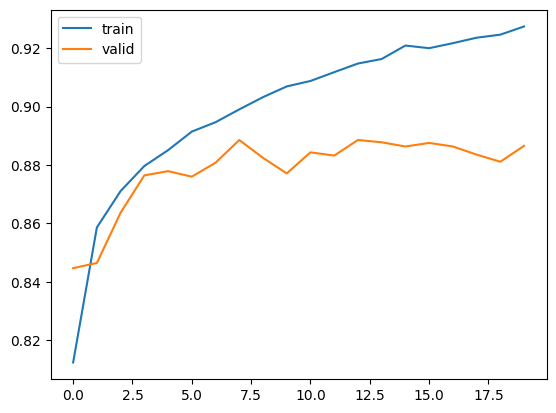

In [45]:
import matplotlib.pyplot as plt
%matplotlib inline

def show_history(history):
    plt.plot(history.history['accuracy'], label='train')
    plt.plot(history.history['val_accuracy'], label='valid')
    plt.legend()

show_history(history)

In [46]:
# 테스트 데이터 세트로 모델 성능 검증
model.evaluate(test_images, test_oh_labels, batch_size=256, verbose=1)

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8820 - loss: 0.3609


[0.36091306805610657, 0.8820000290870667]

In [ ]:
'''
======================================================================
Keras.Callback
-------------------------------------------------------------------------     
ModelCheckpoint : 특정 조건에 맞춰서 모델을 파일로 저장함

ModelCheckpoint(filepath, 
                monitor='val_loss', 
                verbose=0, 
                save_best_only=False,
                save_weights_only=False, 
                mode='auto', 
                period=1) # period: 최신 케라스 버전에서 삭제

 - filepath : 
 - monitor : 모니터할 지표 (loss 또는 평가지표)
 - save_best_only : 가장 좋은 성능을 나타내는 모델만 저장할 여부
 - save_weights_only : weights만 저장할 지 여부
 - mode :  (auto | min | max) 중 하나.  
            monitor 지표가 감소해야 좋을 경우 min, 
            증가해야 좋을 경우 max,
            auto는 monitor 이름에서 자동으로 유추.

-------------------------------------------------------------------------            
ReduceLROnPlateau : 특정 epochs 횟수동안 성능이 개선되지 않을 시 learning rate를 동적으로 감소시킴. 

ReduceLROnPlateau(monitor='val_loss', factor=0.1, 
                  patience=10, verbose=0,
                  mode='auto', min_delta=0.0001, cooldown=0, min_lr=0)

- monitor : 모니터 할 지표
- factor :  학습 속도를 줄일 인수, new_lr = lr * factor
- patience : learning rate를 줄이기 전에 monitor할 epochs 횟수
- mode :   (auto | min | max) 중 하나.  
            monitor 지표가 감소해야 좋을 경우 min, 
            증가해야 좋을 경우 max,
            auto는 monitor 이름에서 자동으로 유추.

-------------------------------------------------------------------------
EarlyStopping : 특정 epochs 동안 성능이 개선되지 않을 시 학습을 조기에 중단
EarlyStopping(monitor='val_loss',
              min_delta=0,
              patience=0,
              verbose=0,
              mode='auto',
              baseline=None,
              restore_best_weights=False)

- monitor : 모니터할 지표(loss 또는 평가지표)
- patience : Early Stopping 적용 전, monitor할 epochs 횟수
- mode :   (auto | min | max) 중 하나.  
            monitor 지표가 감소해야 좋을 경우 min, 
            증가해야 좋을 경우 max,
            auto는 monitor 이름에서 자동으로 유추.
            
======================================================================
'''

In [47]:
!pwd

9926.13s - pydevd: Sending message related to process being replaced timed-out after 5 seconds
/kaggle/working


In [ ]:
# ModelCheckpoint()
from tensorflow.keras.callbacks import ModelCheckpoint

model = create_model()
model.compile(optimizer=Adam(0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

mcp_cb = ModelCheckpoint(filepath='/kaggle/working/weights.{epoch:02d}-{val_loss:.2f}.weights.h5',
                         monitor='val_loss',
                         save_best_only=True,
                         save_weights_only=True,
                         mode='min',
                         verbose=1)

history = model.fit(x=tr_images, 
                    y=tr_oh_labels, 
                    batch_size=128, 
                    validation_data=(val_images, val_oh_labels),
                    callbacks=[mcp_cb])



399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6973 - loss: 0.8897
Epoch 1: val_loss improved from None to 0.45491, saving model to /kaggle/working/weights.01-0.45.weights.h5

Epoch 1: finished saving model to /kaggle/working/weights.01-0.45.weights.h5
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7885 - loss: 0.6145 - val_accuracy: 0.8374 - val_loss: 0.4549


In [ ]:
# !ls -lia
# !rm -rf weight*
# !ls -lia

In [54]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

model = create_model()
model.compile(optimizer=Adam(0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

rlr_cb = ReduceLROnPlateau(monitor='val_loss',
                         factor=0.3,
                         patience=3,
                         mode='min',
                         verbose=1)

history = model.fit(x=tr_images,
                    y=tr_oh_labels, 
                    batch_size=128, 
                    epochs=30,
                    validation_data=(val_images, val_oh_labels),
                    callbacks=[rlr_cb])

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8000 - loss: 0.6002 - val_accuracy: 0.8333 - val_loss: 0.4577 - learning_rate: 0.0010
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8562 - loss: 0.4164 - val_accuracy: 0.8516 - val_loss: 0.4198 - learning_rate: 0.0010
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8692 - loss: 0.3724 - val_accuracy: 0.8563 - val_loss: 0.3926 - learning_rate: 0.0010
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8749 - loss: 0.3497 - val_accuracy: 0.8660 - val_loss: 0.3736 - learning_rate: 0.0010
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8821 - loss: 0.3328 - val_accuracy: 0.8670 - val_loss: 0.3641 - learning_rate: 0.0010
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8872 - loss: 0.3131 - val_accuracy: 0.8586 - val_loss: 0.3967 - learning_rate: 0.0010
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8900 - loss: 0.3034 - 

In [55]:
from tensorflow.keras.callbacks import EarlyStopping

model = create_model()
model.compile(optimizer=Adam(0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

ely_cb = EarlyStopping(monitor='val_loss',
                         patience=3,
                         mode='min',
                         verbose=1)

history = model.fit(x=tr_images,
                    y=tr_oh_labels, 
                    batch_size=128, 
                    epochs=30,
                    validation_data=(val_images, val_oh_labels),
                    callbacks=[ely_cb])

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7901 - loss: 0.6140 - val_accuracy: 0.8444 - val_loss: 0.4501
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8544 - loss: 0.4128 - val_accuracy: 0.8449 - val_loss: 0.4288
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8676 - loss: 0.3716 - val_accuracy: 0.8620 - val_loss: 0.3828
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8770 - loss: 0.3428 - val_accuracy: 0.8699 - val_loss: 0.3588
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8829 - loss: 0.3245 - val_accuracy: 0.8682 - val_loss: 0.3656
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8871 - loss: 0.3086 - val_accuracy: 0.8783 - val_loss: 0.3402
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8903 - loss: 0.2999 - val_accuracy: 0.8776 - val_loss: 0.3466
Epoch 8/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8960 - loss: 0.2860 - val_accuracy: 0.

In [56]:
! rm weigh*

12166.28s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


In [57]:
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping

model = create_model()
model.compile(optimizer=Adam(0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

mcp_cb = ModelCheckpoint(filepath='/kaggle/working/weights.{epoch:02d}-{val_loss:.2f}.weights.h5',
                         monitor='val_loss',
                         save_best_only=True,
                         save_weights_only=True,
                         mode='min',
                         verbose=1)

ely_cb = EarlyStopping(monitor='val_loss',
                         patience=3,
                         mode='min',
                         verbose=1)

rlr_cb = ReduceLROnPlateau(monitor='val_loss',
                         factor=0.3,
                         patience=3,
                         mode='min',
                         verbose=1)

history = model.fit(x=tr_images,
                    y=tr_oh_labels, 
                    batch_size=128, 
                    epochs=40,
                    validation_data=(val_images, val_oh_labels),
                    callbacks=[mcp_cb, rlr_cb, ely_cb])

Epoch 1/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6990 - loss: 0.9023
Epoch 1: val_loss improved from None to 0.46635, saving model to /kaggle/working/weights.01-0.47.weights.h5

Epoch 1: finished saving model to /kaggle/working/weights.01-0.47.weights.h5
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7908 - loss: 0.6172 - val_accuracy: 0.8272 - val_loss: 0.4663 - learning_rate: 0.0010
Epoch 2/40
388/399 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8509 - loss: 0.4255
Epoch 2: val_loss improved from 0.46635 to 0.40434, saving model to /kaggle/working/weights.02-0.40.weights.h5

Epoch 2: finished saving model to /kaggle/working/weights.02-0.40.weights.h5
399/399 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8542 - loss: 0.4145 - val_accuracy: 0.8544 - val_loss: 0.4043 - learning_rate: 0.0010
Epoch 3/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8645 - loss: 0.3810
Epoch 3: val_loss improved from 0.40434 to 0.37976, saving model to /kaggle/working/w